# Phần 2 – Khai phá quy trình trên BPMN và nhật ký của text2BPMN

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Punpunpuong22/final_report_texttobpmn_proces_mining/blob/main/notebooks/Part2_ProcessMining.ipynb)

Notebook chạy pipeline tám bước trên một tệp BPMN do text2BPMN xuất:

| Bước | Câu hỏi | Đầu ra |
|---|---|---|
| 1 | BPMN có hợp lệ về hành vi (sound) không? | Bảng phần tử, soundness, lỗi cấu trúc |
| 2 | Lấy nhật ký sự kiện | Log CSV/XES theo kịch bản, kiểm tra chất lượng |
| 3 | Quy trình chạy thế nào? | KPI, tỷ trọng thời gian làm việc, biến thể |
| 4 | Khám phá mô hình từ log | DFG, Inductive, Heuristics, bốn chỉ số chất lượng |
| 5 | Vận hành có đúng BPMN và quy định? | Alignment, vi phạm luật |
| 6 | Điểm nghẽn ở đâu? | Chờ và xử lý, tải từng làn, hàng đợi |
| 7 | Yếu tố nào gắn với trễ hạn? | Cây quyết định |
| 8 | TO-BE có tốt hơn không, nhờ thay đổi nào? | BPMN TO-BE, so sánh có kiểm định, ablation |

**Chạy trên Colab:** Runtime → Run all. **Chạy trên Kaggle:** bật *Internet* trong Settings của notebook rồi Run all.

> Nhật ký mặc định là **dữ liệu mô phỏng** với tham số giả định. Kết quả minh hoạ phương pháp, không phải số liệu vận hành thật.

## 0. Cài đặt môi trường

In [1]:
# Kho GitHub của nhóm. Ô này tự clone kho nếu chưa có mã nguồn.
REPO_URL = "https://github.com/Punpunpuong22/final_report_texttobpmn_proces_mining.git"
REPO_NAME = "final_report_texttobpmn_proces_mining"

import glob, os, shutil, subprocess, sys, zipfile
os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "False"

IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.isdir("/kaggle/working")

def find_repo():
    """Tìm thư mục chứa mã nguồn: thư mục hiện tại, thư mục cha, bản đã clone, tệp zip tải lên, hoặc dataset Kaggle."""
    for d in [os.getcwd(), os.path.dirname(os.getcwd()), "/content/" + REPO_NAME, "/kaggle/working/" + REPO_NAME]:
        if os.path.isdir(os.path.join(d, "src", "text2bpmn_mining")):
            return d
    base = "/content" if IN_COLAB else "/kaggle/working" if IN_KAGGLE else os.getcwd()
    for z in glob.glob(os.path.join(base, "*.zip")) + glob.glob("/kaggle/input/**/*.zip", recursive=True):
        with zipfile.ZipFile(z) as f:
            f.extractall(base)
    for d in glob.glob(os.path.join(base, "**", "src", "text2bpmn_mining"), recursive=True) + \
             glob.glob("/kaggle/input/**/src/text2bpmn_mining", recursive=True):
        root = os.path.dirname(os.path.dirname(d))
        if root.startswith("/kaggle/input"):                 # dataset Kaggle chỉ đọc → chép sang /kaggle/working
            dst = "/kaggle/working/" + REPO_NAME
            shutil.copytree(root, dst, dirs_exist_ok=True)
            root = dst
        return root
    if REPO_URL:
        dst = os.path.join(base, REPO_NAME)
        subprocess.run(["git", "clone", "-q", REPO_URL, dst], check=True)
        return dst
    raise SystemExit("Không tìm thấy mã nguồn. Sửa REPO_URL, hoặc tải tệp zip của kho lên (Colab: thanh Files; "
                     "Kaggle: Add Data) rồi chạy lại ô này.")

ROOT = find_repo()
os.chdir(ROOT)
sys.path.insert(0, os.path.join(ROOT, "src"))

try:
    import pm4py  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
if shutil.which("dot") is None and (IN_COLAB or IN_KAGGLE):   # graphviz để vẽ DFG và BPMN
    subprocess.run("apt-get -qq update && apt-get -qq install -y graphviz > /dev/null", shell=True)

import pandas as pd
import pm4py
import text2bpmn_mining as t2b
try:
    from IPython.display import Image, display
except ImportError:                                              # chạy ngoài notebook
    display, Image = print, (lambda filename: filename)
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 170)

def show(path):
    if os.path.exists(path):
        display(Image(filename=path))

print("Thư mục:", ROOT, "| pm4py", pm4py.__version__, "| text2bpmn_mining", t2b.__version__)



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




Thư mục: /content/final_report_texttobpmn_proces_mining | pm4py 2.7.23.11 | text2bpmn_mining 1.0.0


## Cấu hình

Chọn tệp BPMN cần phân tích. Ba tệp mẫu do text2BPMN xuất nằm trong `data/bpmn/`.
Nếu đã có nhật ký do text2BPMN xuất, đặt các tệp CSV/XES vào `data/part1_logs/<tên tệp BPMN>/`
(mỗi tệp là một kịch bản); pipeline sẽ dùng nhật ký đó thay cho bộ mô phỏng.

Mọi tham số trong `Config` là giả định và có thể sửa: số hồ sơ, thời gian từng bước, số người mỗi làn,
kịch bản, thời hạn, luật nghiệp vụ, bước đề xuất tự động hoá.

In [2]:
BPMN_FILE = "data/bpmn/quy-trinh-nghi-phep.bpmn"     # hoặc quy-trinh-tuyen-dung.bpmn, quy-trinh-dat-hang.bpmn

cfg = t2b.Config(
    seed=42,
    n_cases=200,            # số hồ sơ mỗi kịch bản
    n_rep=10,               # số lần lặp khi so sánh AS-IS và TO-BE (giảm xuống 3 để chạy nhanh)
    sla_minutes=None,       # thời hạn (phút); None = 1,5 × P90 thời gian lưu trú của kịch bản đầu
    task_minutes={},        # ghi đè thời gian từng bước, vd {"Xem xét đơn": 25}
    capacity=None,          # số người mỗi làn, vd {"Quản lý": 2}; None = 1 người mỗi làn
)
p = t2b.Pipeline(BPMN_FILE, cfg=cfg)
print("Quy trình:", p.M["name"], "| làn:", p.M["lanes"], "| đầu ra:", p.out)
print("Luật:", p.cfg.rules, "| tự động hoá (C3):", p.cfg.automate or "–", "| sửa luồng (C0):", p.cfg.repair_flows or "–")
display(pd.DataFrame(t2b.DEFAULT_SCENARIOS).T)

Quy trình: Quy trình nghỉ phép | làn: ['Nhân sự', 'Quản lý'] | đầu ra: outputs/quy-trinh-nghi-phep
Luật: [('truoc', 'Xem xét đơn', 'Ghi nhận nghỉ phép'), ('truoc', 'Xem xét đơn', 'Ghi lý do từ chối'), ('khac_nguoi', 'Xem xét đơn', 'Ghi nhận nghỉ phép')] | tự động hoá (C3): Ghi nhận nghỉ phép | sửa luồng (C0): –


,p_positive,p_rework,mean_gap,deviation
S1_suon_se,0.9,0.05,40.0,0.0
S2_truc_trac,0.3,0.33,40.0,0.0
S3_qua_tai,0.9,0.05,25.0,0.0
S4_vi_pham,0.9,0.05,40.0,0.1


## Bước 1 – Kiểm tra cấu trúc và soundness

BPMN hợp lệ **cú pháp** chưa chắc hợp lệ **hành vi**. Mô hình được chuyển sang mạng Petri và kiểm tra bằng Woflan;
đồng thời dò các lỗi hay gặp khi mô tả quy trình bằng lời: rẽ nhánh hoặc hội tụ ngầm ở một công việc, nhánh XOR thiếu
hoặc trùng nhãn, nhãn giữ chỗ chưa sửa, công việc của hệ thống đặt trong làn của người.

,id,type,name,lane,vào,ra
0,P1_StartEvent_s1,startEvent,Gửi đơn nghỉ phép,Nhân viên,0,1
1,P1_Task_t1,task,Xem xét đơn,Quản lý,1,1
2,P1_Gateway_x1,exclusiveGateway,Quản lý đồng ý?,Quản lý,1,2
3,P1_UserTask_u1,userTask,Ghi nhận nghỉ phép,Nhân sự,1,1
4,P1_Task_t2,task,Ghi lý do từ chối,Quản lý,1,1
5,P1_EndEvent_e1,endEvent,Nhận thông báo đã duyệt,Nhân viên,1,0
6,P1_EndEvent_e2,endEvent,Nhận thông báo từ chối,Nhân viên,1,0


,id,tu,den,nhan
0,P1_Flow_1,Gửi đơn nghỉ phép,Xem xét đơn,
1,P1_Flow_2,Xem xét đơn,Quản lý đồng ý?,
2,P1_Flow_3,Quản lý đồng ý?,Ghi nhận nghỉ phép,Đồng ý
3,P1_Flow_4,Quản lý đồng ý?,Ghi lý do từ chối,Từ chối
4,P1_Flow_5,Ghi nhận nghỉ phép,Nhận thông báo đã duyệt,
5,P1_Flow_6,Ghi lý do từ chối,Nhận thông báo từ chối,


Sound (Woflan): True


'Không phát hiện vấn đề cấu trúc.'

Một số vết mô hình cho phép:


,vet,so_lan
0,Xem xét đơn → Ghi nhận nghỉ phép,21
1,Xem xét đơn → Ghi lý do từ chối,9


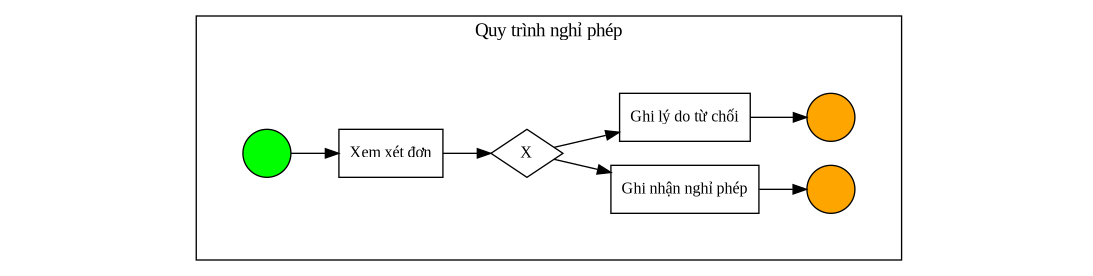

In [3]:
r1 = p.step1_structure()
display(r1["elements"]); display(r1["flows"])
print("Sound (Woflan):", r1["sound"])
display(r1["issues"] if len(r1["issues"]) else "Không phát hiện vấn đề cấu trúc.")
print("Một số vết mô hình cho phép:"); display(r1["traces"])
show(f"{p.out}/fig_bpmn_AS_IS.png")

## Bước 2 – Nhật ký sự kiện

Ưu tiên nhật ký do text2BPMN xuất. Nếu chưa có, bộ mô phỏng chạy token trên chính BPMN với bốn kịch bản,
thêm hai yếu tố mà text2BPMN chưa có: hồ sơ đến theo thời gian và số người mỗi làn, để có hàng đợi và thời gian chờ.
Sau đó kiểm tra chất lượng: thiếu cột, giá trị rỗng, thời gian ngược, dòng trùng, hồ sơ bắt đầu hoặc kết thúc sai.

In [4]:
r2 = p.step2_event_log()
print("Nguồn:", r2["source"], "| kích thước:", r2["shape"])
display(p.events.head(6))
display(r2["quality"])

/usr/local/lib/python3.13/dist-packages/pm4py/utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(


Nguồn: bộ mô phỏng của Phần 2 | kích thước: (1819, 13)


,case_id,activity,enable_ts,start_ts,end_ts,resource,role,task_type,scenario,arrival,n_lam_lai,ket_qua,sai_lech
0,S1_suon_se_0000,Xem xét đơn,2026-03-02 08:40:48.144689,2026-03-02 08:40:48.144689,2026-03-02 08:55:51.697073,Quản lý_1,Quản lý,task,S1_suon_se,2026-03-02 08:40:48.144689,0,Nhận thông báo đã duyệt,none
1,S1_suon_se_0000,Ghi nhận nghỉ phép,2026-03-02 08:55:51.697073,2026-03-02 08:55:51.697073,2026-03-02 09:14:28.741995,Nhân sự_1,Nhân sự,userTask,S1_suon_se,2026-03-02 08:40:48.144689,0,Nhận thông báo đã duyệt,none
2,S1_suon_se_0001,Xem xét đơn,2026-03-02 08:41:48.933903,2026-03-02 08:55:51.697073,2026-03-02 09:10:04.546815,Quản lý_1,Quản lý,task,S1_suon_se,2026-03-02 08:41:48.933903,0,Nhận thông báo đã duyệt,none
3,S1_suon_se_0001,Ghi nhận nghỉ phép,2026-03-02 09:10:04.546815,2026-03-02 09:14:28.741995,2026-03-02 10:00:32.659799,Nhân sự_1,Nhân sự,userTask,S1_suon_se,2026-03-02 08:41:48.933903,0,Nhận thông báo đã duyệt,none
4,S1_suon_se_0002,Xem xét đơn,2026-03-02 08:54:40.831657,2026-03-02 09:10:04.546815,2026-03-02 09:24:42.731664,Quản lý_1,Quản lý,task,S1_suon_se,2026-03-02 08:54:40.831657,0,Nhận thông báo đã duyệt,none
5,S1_suon_se_0002,Ghi nhận nghỉ phép,2026-03-02 09:24:42.731664,2026-03-02 10:00:32.659799,2026-03-02 10:38:18.241926,Nhân sự_1,Nhân sự,userTask,S1_suon_se,2026-03-02 08:54:40.831657,0,Nhận thông báo đã duyệt,none


,S1_suon_se,S2_truc_trac,S3_qua_tai,S4_vi_pham
thiếu cột,[],[],[],[]
rỗng,0,0,0,0
end < start,0,0,0,0
trùng,0,0,0,0
bắt đầu sai,0,0,0,15
kết thúc sai/dở dang,0,0,0,20
hoạt động lạ,[],[],[],[]


## Bước 3 – Thống kê mô tả

*Thời gian làm việc* là tổng thời gian xử lý các bước, đúng chỉ số text2BPMN hiển thị. *Thời gian lưu trú* tính từ lúc
nộp đến lúc xong, gồm cả thời gian chờ. Bảng tỷ trọng dùng để đối chiếu với thanh "bước tốn thời gian nhất" của text2BPMN.

Thời hạn (giả định): 284 phút


,so_ho_so,so_bien_the,lam_viec_tb,cycle_tb,cycle_p90,ty_le_tre_han,lam_lai_tb
scenario,,,,,,,
S1_suon_se,200,6,53.06,111.54,189.62,0.00,0.11
S2_truc_trac,200,19,60.68,964.23,1860.24,0.96,0.81
S3_qua_tai,200,8,51.70,688.82,1171.32,0.78,0.12
S4_vi_pham,200,12,50.73,92.33,159.56,0.00,0.14


scenario,S1_suon_se,S2_truc_trac,S3_qua_tai,S4_vi_pham
activity,,,,
Ghi lý do từ chối,0.03,0.31,0.04,0.03
Ghi nhận nghỉ phép,0.58,0.20,0.55,0.56
Xem xét đơn,0.39,0.49,0.41,0.41


,variant,ty_le,scenario
0,Xem xét đơn → Ghi nhận nghỉ phép,0.825,S1_suon_se
1,Xem xét đơn → Ghi lý do từ chối,0.070,S1_suon_se
2,Xem xét đơn → Xem xét đơn → Ghi nhận nghỉ phép,0.050,S1_suon_se
3,Xem xét đơn → Ghi lý do từ chối,0.320,S2_truc_trac
4,Xem xét đơn → Ghi nhận nghỉ phép,0.155,S2_truc_trac
5,Xem xét đơn → Ghi lý do từ chối → Ghi lý do từ...,0.110,S2_truc_trac
6,Xem xét đơn → Ghi nhận nghỉ phép,0.810,S3_qua_tai
7,Xem xét đơn → Ghi lý do từ chối,0.095,S3_qua_tai
8,Xem xét đơn → Xem xét đơn → Ghi nhận nghỉ phép,0.040,S3_qua_tai
9,Xem xét đơn → Ghi nhận nghỉ phép,0.705,S4_vi_pham


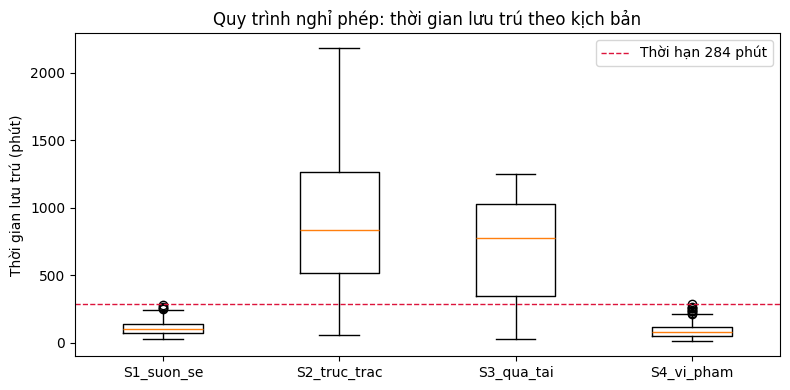

In [5]:
r3 = p.step3_describe()
print("Thời hạn (giả định):", r3["sla"], "phút")
display(r3["kpi"]); display(r3["work_share"]); display(r3["top_variants"])

## Bước 4 – Khám phá quy trình
Đánh giá trên chính nhật ký dùng để khám phá (in-sample), nên các chỉ số có xu hướng lạc quan.

,scenario,thuat_toan,fitness,pct_vet_khop,precision,generalization,simplicity
0,S1_suon_se,Inductive (IMf 0.2),1.000,100.0,0.976,0.778,0.793
1,S1_suon_se,Heuristics (0.9),0.861,7.0,0.968,0.899,0.750
2,S2_truc_trac,Inductive (IMf 0.2),1.000,100.0,0.993,0.896,0.793
3,S2_truc_trac,Heuristics (0.9),0.911,0.0,0.992,0.910,0.684
4,S3_qua_tai,Inductive (IMf 0.2),1.000,100.0,0.998,0.861,0.800
5,S3_qua_tai,Heuristics (0.9),0.865,9.5,0.997,0.903,0.750
6,S4_vi_pham,Inductive (IMf 0.2),0.971,85.0,0.971,0.751,0.733
7,S4_vi_pham,Heuristics (0.9),0.989,94.5,1.000,0.833,0.667


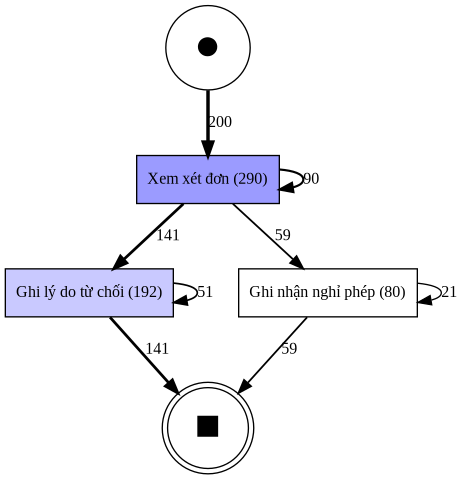

In [6]:
r4 = p.step4_discovery()
display(r4["discovery"])
show(r4["dfg_images"][1] if len(r4["dfg_images"]) > 1 else r4["dfg_images"][0])

## Bước 5 – Kiểm tra tuân thủ

*Log move* là bước có trong nhật ký nhưng mô hình không cho phép (gồm cả làm lại, vì BPMN không có vòng lặp);
*model move* là bước mô hình đòi hỏi nhưng bị bỏ qua. Bảng luật cho tỷ lệ hồ sơ **vi phạm** từng luật.

In [7]:
r5 = p.step5_conformance()
display(r5["fitness"]); display(r5["deviations"]); display(r5["rule_violations"])

,fitness_tb,khop_hoan_toan
scenario,,
S1_suon_se,0.978,0.895
S2_truc_trac,0.860,0.475
S3_qua_tai,0.978,0.905
S4_vi_pham,0.924,0.760


scenario                                                S1_suon_se  S2_truc_trac  S3_qua_tai  S4_vi_pham
loai                                hoat_dong                                                           
Log move – làm thừa/sai chỗ/làm lại Ghi lý do từ chối          1.0          51.0         0.0         5.0
                                    Ghi nhận nghỉ phép        11.0          21.0        10.0        14.0
                                    Xem xét đơn               10.0          90.0        13.0        18.0
Model move – bỏ bước                Ghi nhận nghỉ phép         0.0           0.0         0.0        10.0
                                    Xem xét đơn                0.0           0.0         0.0        15.0

,Xem xét đơn trước Ghi nhận nghỉ phép,Xem xét đơn trước Ghi lý do từ chối,Xem xét đơn ≠ người Ghi nhận nghỉ phép,Không làm lại,Đúng hạn
scenario,,,,,
S1_suon_se,0.000,0.0,0.0,0.105,0.000
S2_truc_trac,0.000,0.0,0.0,0.525,0.965
S3_qua_tai,0.000,0.0,0.0,0.095,0.780
S4_vi_pham,0.075,0.0,0.0,0.120,0.005


## Bước 6 – Điểm nghẽn

Xếp hạng theo **tổng thời gian chờ** (bắt đầu − sẵn sàng), không theo thời gian làm việc. Mức tải từng làn giải thích
vì sao hàng đợi hình thành.

=== S1_suon_se | tải làn: {'Nhân sự': 0.76, 'Quản lý': 0.56}


,lane,tan_suat,cho_tb,cho_p90,xu_ly_tb,tong_cho,tong_xu_ly,ty_trong_cho,ty_trong_lam_viec
activity,,,,,,,,,
Ghi nhận nghỉ phép,Nhân sự,196,40.12,104.73,31.25,7864.33,6125.18,0.67,0.58
Xem xét đơn,Quản lý,210,16.51,50.27,19.92,3467.93,4182.53,0.30,0.39
Ghi lý do từ chối,Quản lý,16,22.69,54.74,19.07,363.07,305.19,0.03,0.03


=== S2_truc_trac | tải làn: {'Quản lý': 1.0, 'Nhân sự': 0.25}


,lane,tan_suat,cho_tb,cho_p90,xu_ly_tb,tong_cho,tong_xu_ly,ty_trong_cho,ty_trong_lam_viec
activity,,,,,,,,,
Xem xét đơn,Quản lý,290,361.63,910.30,20.48,104873.89,5940.54,0.58,0.49
Ghi lý do từ chối,Quản lý,192,393.19,908.72,19.74,75492.93,3790.57,0.42,0.31
Ghi nhận nghỉ phép,Nhân sự,80,4.28,11.58,30.07,342.68,2405.44,0.00,0.20


=== S3_qua_tai | tải làn: {'Nhân sự': 0.99, 'Quản lý': 0.81}


,lane,tan_suat,cho_tb,cho_p90,xu_ly_tb,tong_cho,tong_xu_ly,ty_trong_cho,ty_trong_lam_viec
activity,,,,,,,,,
Ghi nhận nghỉ phép,Nhân sự,190,561.73,1005.34,29.97,106728.71,5694.15,0.84,0.55
Xem xét đơn,Quản lý,213,88.51,159.86,19.71,18852.38,4198.54,0.15,0.41
Ghi lý do từ chối,Quản lý,20,92.19,179.99,22.36,1843.76,447.14,0.01,0.04


=== S4_vi_pham | tải làn: {'Nhân sự': 0.7, 'Quản lý': 0.56}


,lane,tan_suat,cho_tb,cho_p90,xu_ly_tb,tong_cho,tong_xu_ly,ty_trong_cho,ty_trong_lam_viec
activity,,,,,,,,,
Ghi nhận nghỉ phép,Nhân sự,190,25.14,82.89,29.79,4776.45,5660.88,0.60,0.56
Xem xét đơn,Quản lý,203,14.57,49.43,20.47,2958.30,4155.76,0.37,0.41
Ghi lý do từ chối,Quản lý,19,13.08,44.96,17.29,248.58,328.44,0.03,0.03


Điểm nghẽn (S2_truc_trac): Xem xét đơn – làn Quản lý


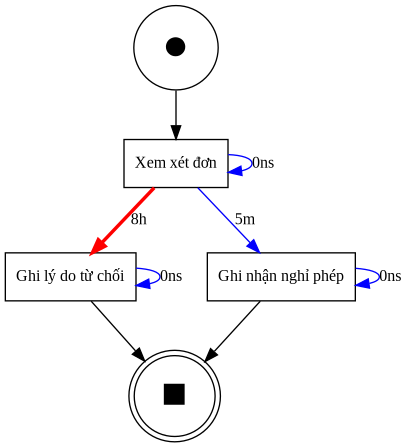

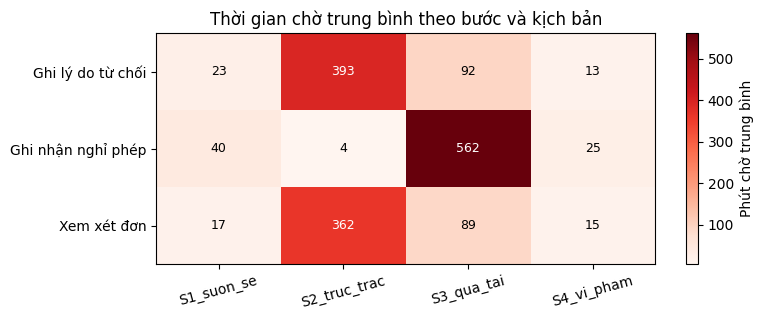

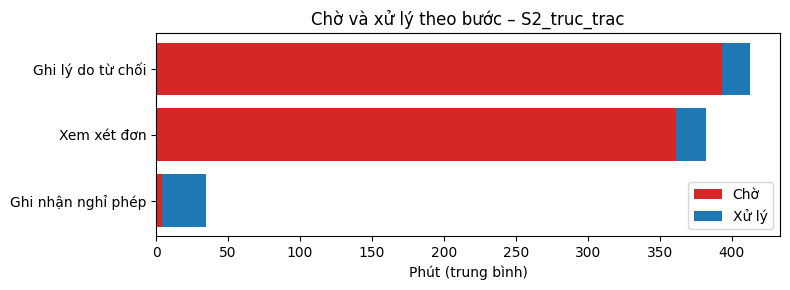

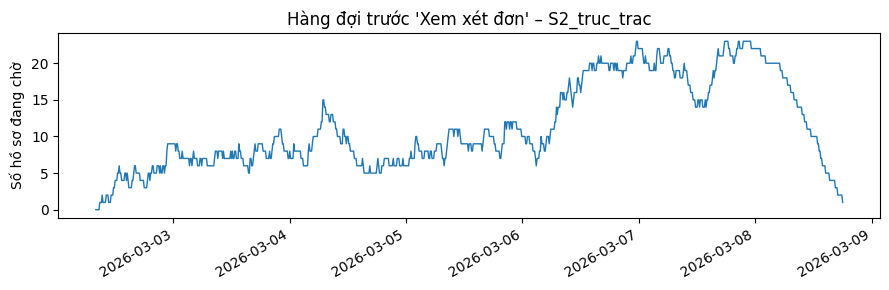

In [8]:
r6 = p.step6_bottleneck()
for s, t in r6["tables"].items():
    print(f"=== {s} | tải làn: {r6['utilization'][s].to_dict()}"); display(t)
print(f"Điểm nghẽn ({r6['hot_scenario']}): {r6['top']} – làn {r6['top_lane']}" if r6["has_queue"]
      else "Không có hàng đợi: mọi bước là việc của hệ thống hoặc năng lực dư.")
show(f"{p.out}/fig_dfg_perf.png")   # biểu đồ matplotlib (heatmap, chờ/xử lý, hàng đợi) hiện ngay bên dưới

## Bước 7 – Yếu tố gắn với trễ hạn
Cây quyết định nông. Kết quả là liên kết thống kê, không phải quan hệ nhân quả; nhân quả được kiểm tra bằng can thiệp ở Bước 8.

In [9]:
r7 = p.step7_root_cause()
print("Số hồ sơ:", r7["n"], "| tỷ lệ trễ hạn:", r7["ty_le_tre_han"], "| balanced accuracy:", r7["bal_acc"])
if r7["tree_text"]:
    print(r7["tree_text"]); display(r7["importance"])
display(r7["by_rework"]); display(r7["by_wip"])

Số hồ sơ: 774 | tỷ lệ trễ hạn: 0.452 | balanced accuracy: 0.968
|--- ton_luc_nop <= 8.50
|   |--- ket_qua_Nhận thông báo đã duyệt <= 0.50
|   |   |--- ton_luc_nop <= 4.50
|   |   |   |--- class: 0
|   |   |--- ton_luc_nop >  4.50
|   |   |   |--- class: 1
|   |--- ket_qua_Nhận thông báo đã duyệt >  0.50
|   |   |--- ton_luc_nop <= 5.50
|   |   |   |--- class: 0
|   |   |--- ton_luc_nop >  5.50
|   |   |   |--- class: 0
|--- ton_luc_nop >  8.50
|   |--- ket_qua_Nhận thông báo đã duyệt <= 0.50
|   |   |--- ton_luc_nop <= 25.50
|   |   |   |--- class: 1
|   |   |--- ton_luc_nop >  25.50
|   |   |   |--- class: 1
|   |--- ket_qua_Nhận thông báo đã duyệt >  0.50
|   |   |--- ton_luc_nop <= 11.50
|   |   |   |--- class: 1
|   |   |--- ton_luc_nop >  11.50
|   |   |   |--- class: 1



,0
ton_luc_nop,0.979
ket_qua_Nhận thông báo đã duyệt,0.021
n_lam_lai,0.000


,mean,size
n_lam_lai,,
0,0.38,607
1,0.63,115
2,0.85,40
3,1.00,10
4,1.00,2


,mean,size
ton_luc_nop,,
"(-1, 2]",0.00,235
"(2, 5]",0.02,141
"(5, 10]",0.41,69
"(10, 20]",0.97,139
"(20, 1000]",0.96,190


## Bước 8 – BPMN TO-BE và đánh giá what-if

| Mã | Căn cứ | Thay đổi |
|---|---|---|
| C0 | Bước 1: BPMN không sound | Xoá các luồng thừa (chỉ khi cần) |
| C1 | Bước 6: làn nghẽn tải cao | Thêm một người cho làn nghẽn của từng kịch bản |
| C2 | Bước 5, 7: làm lại gắn với trễ hạn | Giả định giảm 50% làm lại ở bước làm lại nhiều nhất |
| C3 | Bước 6: bước thủ công tốn thời gian | Tự động hoá (đổi thành serviceTask trên BPMN) |

AS-IS và TO-BE dùng cùng dòng hồ sơ (common random numbers), lặp `n_rep` lần, báo trung bình ± khoảng tin cậy 95%
và kiểm định Wilcoxon theo cặp. Bước này chạy lâu nhất (khoảng 10–30 giây mỗi quy trình).

S1_suon_se: điểm nghẽn 'Ghi nhận nghỉ phép' → C1 thêm người cho làn Nhân sự
S2_truc_trac: điểm nghẽn 'Xem xét đơn' → C1 thêm người cho làn Quản lý
S3_qua_tai: điểm nghẽn 'Ghi nhận nghỉ phép' → C1 thêm người cho làn Nhân sự
Thay đổi: ['C1', 'C2', 'C3'] | bước làm lại nhiều nhất: Xem xét đơn | TO-BE sound: True


cycle_tb       cycle_p90    tre_han lam_viec_tb     cho_tong_tb
scenario     phuong_an                                                                              
S1_suon_se   AS-IS               125.6 ± 28.2    234.6 ± 66.8  0.1 ± 0.1  51.7 ± 0.9     73.8 ± 28.0
             chỉ C1                73.7 ± 3.8     119.3 ± 8.9  0.0 ± 0.0  51.7 ± 0.9      22.0 ± 3.6
             chỉ C2              122.2 ± 26.3    230.8 ± 64.3  0.1 ± 0.1  51.2 ± 0.8     71.0 ± 26.2
             chỉ C3                47.3 ± 3.2      88.5 ± 7.7  0.0 ± 0.0  27.5 ± 0.7      19.8 ± 3.1
             TO-BE (C1+C2+C3)      44.5 ± 2.7      82.7 ± 8.4  0.0 ± 0.0  26.9 ± 0.6      17.5 ± 2.7
S2_truc_trac AS-IS             1518.9 ± 335.3  2822.4 ± 642.3  0.9 ± 0.0  63.1 ± 2.0  1455.8 ± 333.9
             chỉ C1              158.9 ± 41.8   304.3 ± 107.8  0.1 ± 0.1  63.1 ± 2.0     95.8 ± 41.4
             chỉ C2             877.8 ± 241.2  1648.1 ± 441.8  0.8 ± 0.1  57.5 ± 1.4   820.3 ± 240.3
             chỉ C3            1504.8 ± 334.6  2822.4 ± 642.3  0.9 ± 0.0  52.2 ± 1.6  1452.6 ± 333.4
             TO-BE (C1+C2+C3)      79.3 ± 8.8    149.1 ± 18.9  0.0 ± 0.0  46.6 ± 1.4      32.7 ± 8.4
S3_qua_tai   AS-IS              614.5 ± 152.1  1113.9 ± 295.0  0.7 ± 0.1  51.7 ± 0.9   562.7 ± 151.7
             chỉ C1              176.4 ± 45.5    299.9 ± 78.1  0.2 ± 0.1  51.7 ± 0.9    124.6 ± 45.3
             chỉ C2             602.8 ± 149.9  1100.6 ± 286.7  0.7 ± 0.1  51.2 ± 0.8   551.6 ± 149.7
             chỉ C3              147.1 ± 44.8    268.9 ± 76.8  0.1 ± 0.1  27.5 ± 0.7    119.7 ± 44.9
             TO-BE (C1+C2+C3)    128.1 ± 34.7    239.7 ± 59.8  0.1 ± 0.1  26.9 ± 0.6    101.2 ± 35.0

,scenario,asis_tb,tobe_tb,muc_giam,wilcoxon_p
0,S1_suon_se,125.6,44.5,65%,0.002
1,S2_truc_trac,1518.9,79.3,95%,0.002
2,S3_qua_tai,614.5,128.1,79%,0.002


Fitness log TO-BE trên BPMN TO-BE (S2_truc_trac): 0.8961


,AS-IS chờ TB (phút),TO-BE chờ TB (phút)
activity,,
Xem xét đơn,380.4,9.2
Ghi lý do từ chối,389.3,7.4
Ghi nhận nghỉ phép,6.1,0.0


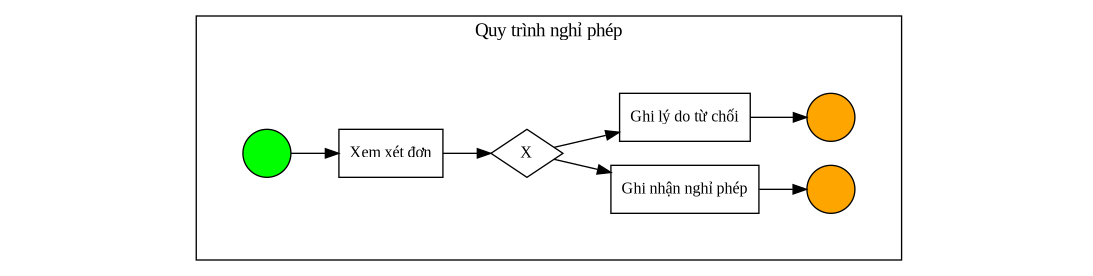

In [10]:
r8 = p.step8_tobe()
print("Thay đổi:", r8["changes"], "| bước làm lại nhiều nhất:", r8["top_rework"], "| TO-BE sound:", r8["tobe_sound"])
display(r8["summary"]); display(r8["wilcoxon"])
print(f"Fitness log TO-BE trên BPMN TO-BE ({r8['verify_scenario']}):", r8["fitness_tobe"])
display(r8["wait_compare"])
show(f"{p.out}/fig_bpmn_TO_BE.png")

## Tải kết quả về
Nén thư mục đầu ra (bảng CSV, hình PNG, log CSV/XES, tệp BPMN TO-BE).

In [11]:
archive = shutil.make_archive(p.out, "zip", p.out)
print("Đã tạo", archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)

Đã tạo /content/final_report_texttobpmn_proces_mining/outputs/quy-trinh-nghi-phep.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Chạy cả ba quy trình cùng lúc (tuỳ chọn)

In [12]:
RUN_ALL = False
if RUN_ALL:
    for f in sorted(glob.glob("data/bpmn/*.bpmn")):
        t2b.Pipeline(f, cfg=t2b.Config(n_rep=10)).run()